In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [7]:
ROOT_DIR = Path.cwd().parent

DATA_PATH = ROOT_DIR / "data" / "processed" / "churn_clean.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print('churn counts:',
      df['Churn'].value_counts())

print('\nChurn Percentage:',
      (df['Churn'].value_counts(normalize=True) * 100).round(2))

churn counts: Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage: Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


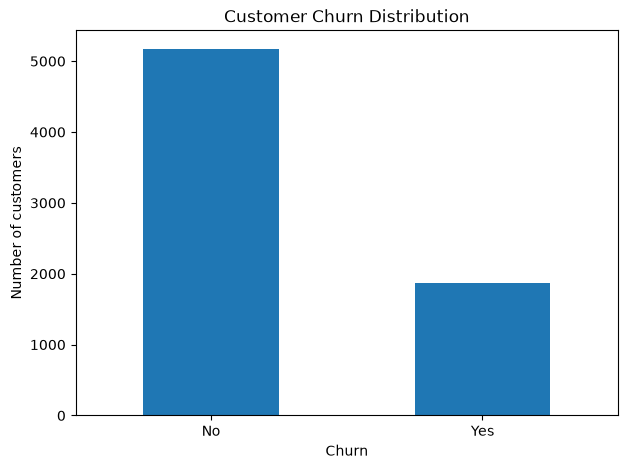

In [9]:
df['Churn'].value_counts().plot(kind='bar', figsize=(7, 5))

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of customers')
plt.xticks(rotation=0)

plt.show()

In [10]:
'''Churn Rate
The churn rate represents the proportion of customers who left the company. Calculating the churn rate helps us understand the overall distribution of the target variable.'''

'Churn Rate\nThe churn rate represents the proportion of customers who left the company. Calculating the churn rate helps us understand the overall distribution of the target variable.'

In [11]:
contract_churn = (pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100
).round(2)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


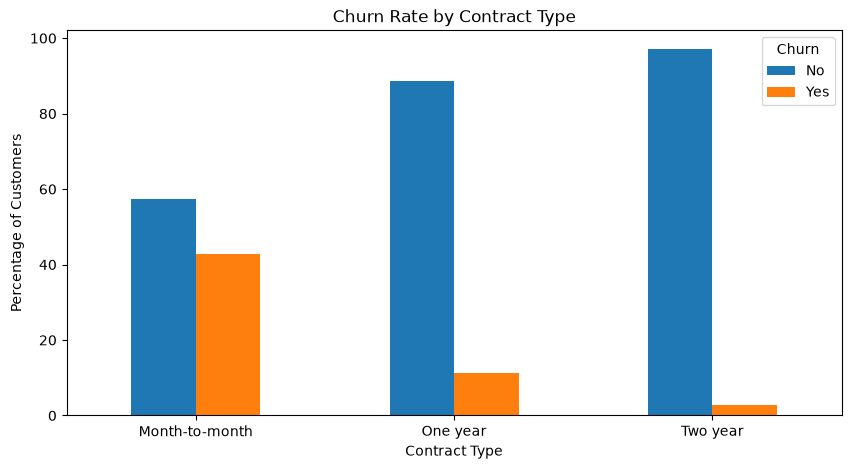

In [12]:
contract_churn.plot(kind='bar', figsize=(10, 5))

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

In [13]:
'''Contract Churn Insight
The analysis shows a clear difference in churn across contract types. Customers with month-to-month contracts have a substantially higher churn rate than customers with one-year or two-year contracts.

This suggests that contract duration may be an important factor associated with customer churn.'''

'Contract Churn Insight\nThe analysis shows a clear difference in churn across contract types. Customers with month-to-month contracts have a substantially higher churn rate than customers with one-year or two-year contracts.\n\nThis suggests that contract duration may be an important factor associated with customer churn.'

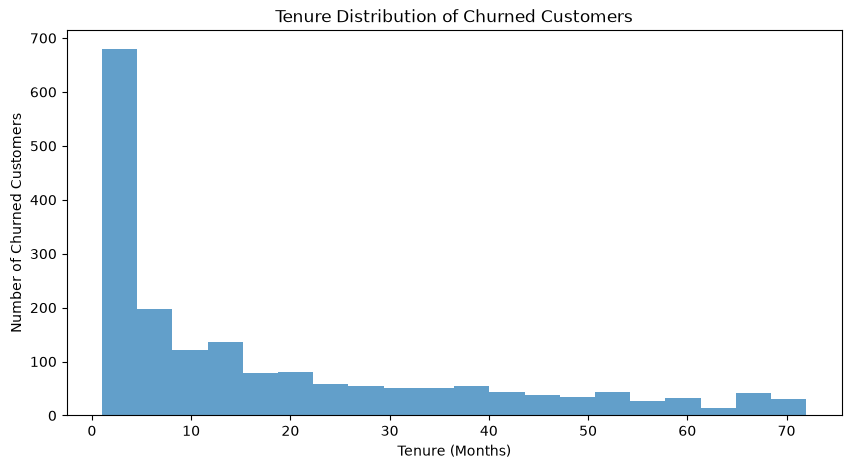

In [14]:
df[df['Churn'] == 'Yes']['tenure'].plot(kind='hist',
                                        bins=20,
                                        alpha=0.7,
                                        figsize=(10, 5)
                                        )

plt.title("Tenure Distribution of Churned Customers")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Churned Customers")

plt.show()

In [15]:
'''Churn Rate by Tenure Group
To better understand the relationship between customer tenure and churn, customers are grouped into tenure ranges and their churn rates are compared.'''

'Churn Rate by Tenure Group\nTo better understand the relationship between customer tenure and churn, customers are grouped into tenure ranges and their churn rates are compared.'

In [16]:
df['tenure'].max()

np.int64(72)

In [17]:
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"]
)

tenure_churn = (
    pd.crosstab(
        df["TenureGroup"],
        df["Churn"],
        normalize="index"
    ) * 100
).round(2)

tenure_churn

Churn,No,Yes
TenureGroup,,
0-12,52.32,47.68
13-24,71.29,28.71
25-48,79.61,20.39
49-60,85.58,14.42
61-72,93.39,6.61


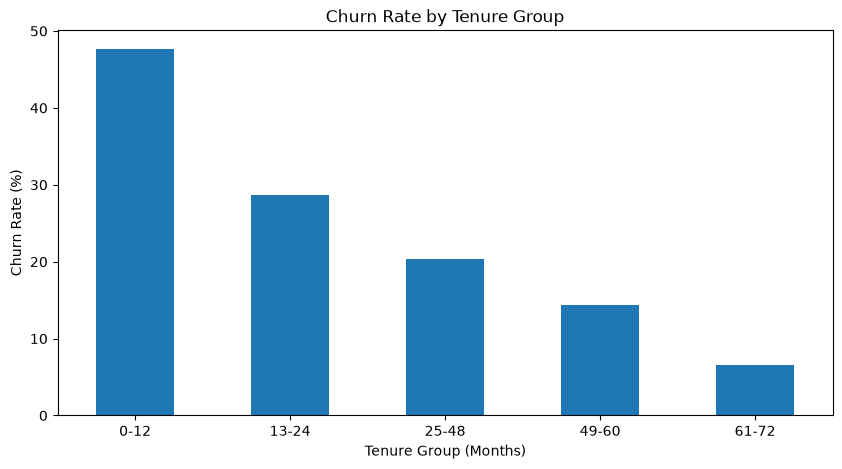

In [18]:
tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [19]:
'''Tenure Churn Insight
The analysis shows that customers with shorter tenure have a higher churn rate than customers with longer tenure. The 0–12 month tenure group has the highest churn rate, while customers with 61–72 months of tenure have the lowest churn rate.

This suggests that customer tenure is an important variable associated with churn behavior.'''

'Tenure Churn Insight\nThe analysis shows that customers with shorter tenure have a higher churn rate than customers with longer tenure. The 0–12 month tenure group has the highest churn rate, while customers with 61–72 months of tenure have the lowest churn rate.\n\nThis suggests that customer tenure is an important variable associated with churn behavior.'

In [20]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

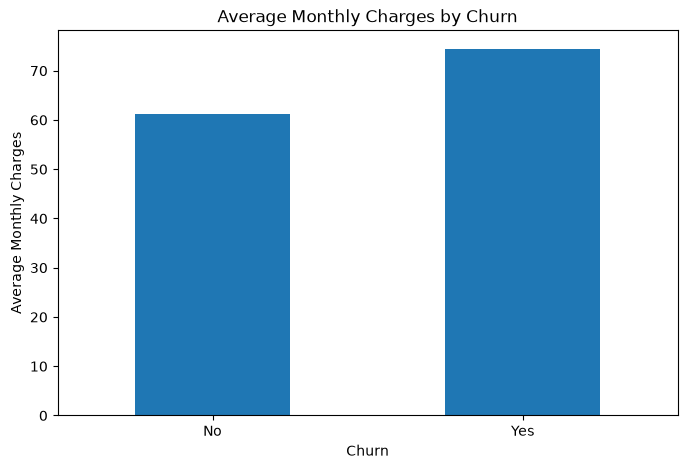

In [21]:
df.groupby("Churn")["MonthlyCharges"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)

plt.show()

In [22]:
'''Monthly Charges Insight
Churned customers have higher average monthly charges than non-churned customers in the dataset. This indicates that monthly charges may be associated with customer churn and can be considered as a useful feature for the prediction model.'''

'Monthly Charges Insight\nChurned customers have higher average monthly charges than non-churned customers in the dataset. This indicates that monthly charges may be associated with customer churn and can be considered as a useful feature for the prediction model.'

In [23]:
df['MonthlyCharges'].max()

np.float64(118.75)

In [24]:
df['ChargesGroup'] = pd.cut(
    df['MonthlyCharges'],
    bins=[0, 30, 60, 90, 120],
    labels=['0-30', '31-60', '61-90', '91-120']
)

churn_rate = pd.crosstab(
    df['ChargesGroup'],
    df['Churn'],
    normalize='index'
) * 100

churn_rate.round(2)

Churn,No,Yes
ChargesGroup,,
0-30,90.20,9.80
31-60,74.07,25.93
61-90,66.09,33.91
91-120,67.22,32.78


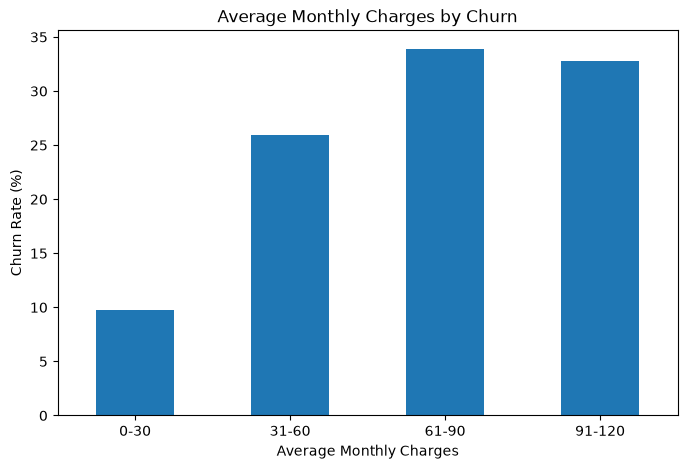

In [25]:
churn_rate['Yes'].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Average Monthly Charges")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [26]:
'''Monthly Charges Insight¶
Churned customers have higher average monthly charges than non-churned customers in the dataset. This indicates that monthly charges may be associated with customer churn and can be considered as a useful feature for the prediction model.'''

'Monthly Charges Insight¶\nChurned customers have higher average monthly charges than non-churned customers in the dataset. This indicates that monthly charges may be associated with customer churn and can be considered as a useful feature for the prediction model.'

In [27]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


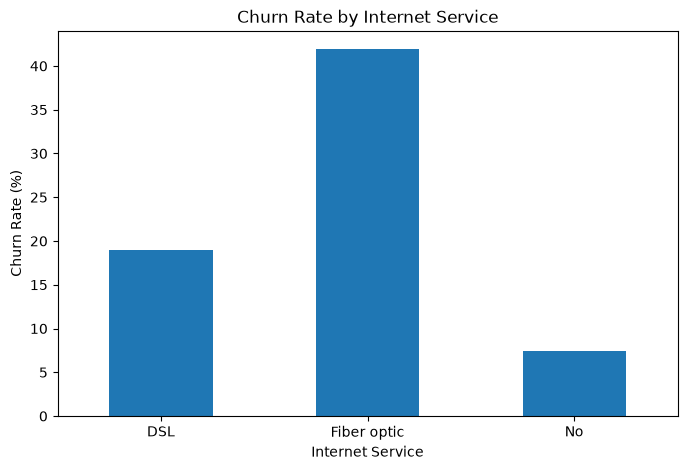

In [28]:
internet_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [29]:
'''Internet Service Churn Insight
The analysis shows differences in churn rates across internet service types. Fiber optic customers have the highest churn rate among the internet service categories, followed by DSL customers.

This indicates that internet service type may be an important feature for predicting customer churn.'''

'Internet Service Churn Insight\nThe analysis shows differences in churn rates across internet service types. Fiber optic customers have the highest churn rate among the internet service categories, followed by DSL customers.\n\nThis indicates that internet service type may be an important feature for predicting customer churn.'

In [30]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


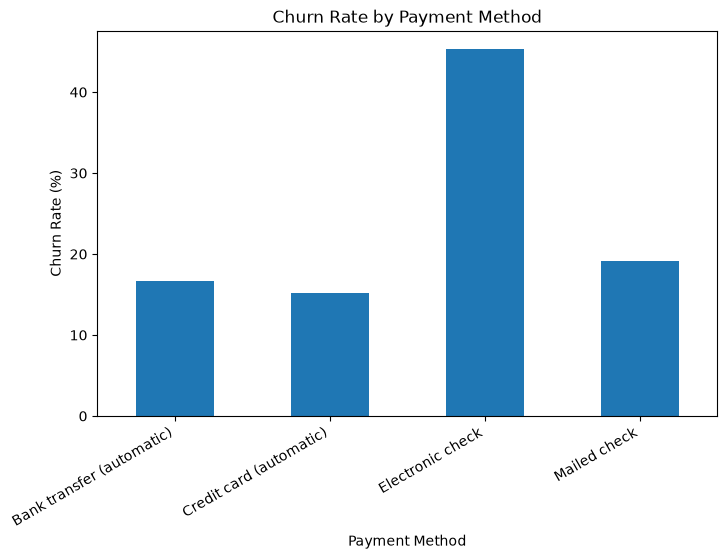

In [31]:
payment_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")

plt.show()

In [32]:
'''Payment Method Churn Insight
The analysis shows noticeable differences in churn rates across payment methods. Customers using electronic checks have the highest churn rate among the payment methods, while customers using automatic payment methods have lower churn rates.

Payment method may therefore provide useful information for predicting customer churn.'''

'Payment Method Churn Insight\nThe analysis shows noticeable differences in churn rates across payment methods. Customers using electronic checks have the highest churn rate among the payment methods, while customers using automatic payment methods have lower churn rates.\n\nPayment method may therefore provide useful information for predicting customer churn.'

In [33]:
techsupport_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

techsupport_churn

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


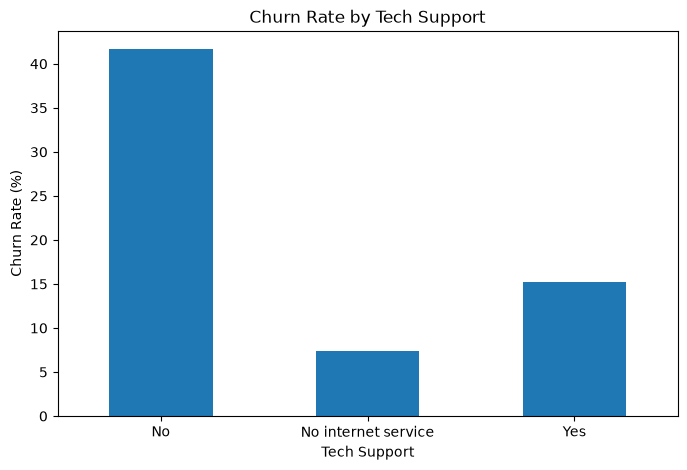

In [34]:
techsupport_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [35]:
'''Tech Support Churn Insight
The analysis shows a substantial difference in churn rates across TechSupport categories. Customers without tech support have a much higher churn rate than customers with tech support.

This indicates that TechSupport status is associated with customer churn and may be a useful feature for the prediction model.'''

'Tech Support Churn Insight\nThe analysis shows a substantial difference in churn rates across TechSupport categories. Customers without tech support have a much higher churn rate than customers with tech support.\n\nThis indicates that TechSupport status is associated with customer churn and may be a useful feature for the prediction model.'

In [36]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


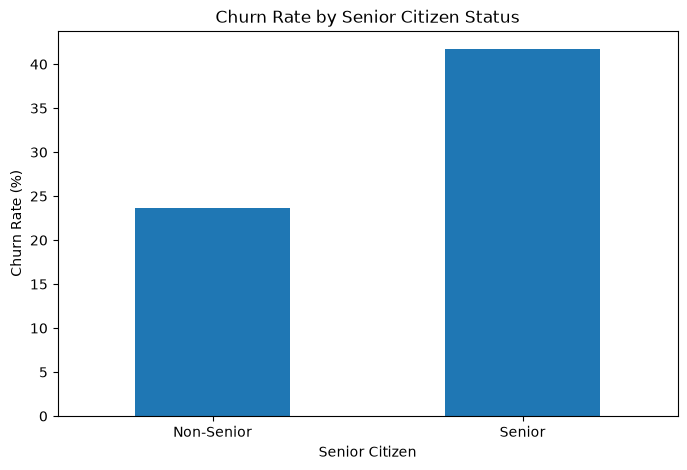

In [37]:
senior_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")
plt.xticks(
    [0, 1],
    ["Non-Senior", "Senior"],
    rotation=0
)

plt.show()

In [38]:
'''Senior Citizen Churn Insight
The analysis shows a higher churn rate among senior citizens compared with non-senior customers in the dataset. This indicates that senior citizen status is associated with customer churn and may provide useful information for the prediction model.'''

'Senior Citizen Churn Insight\nThe analysis shows a higher churn rate among senior citizens compared with non-senior customers in the dataset. This indicates that senior citizen status is associated with customer churn and may provide useful information for the prediction model.'